## Setup and load data

In [1]:
!pip install -q mediapipe tqdm

In [2]:
import os, json, zipfile, requests, warnings, random
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 200); pd.set_option('display.width', 200)
random.seed(42); np.random.seed(42)

DATA_DIR = '/content/data'
ROOT = os.path.join(DATA_DIR, 'Pakistan Sign Language Urdu Alphabets')
OUT = '/content/outputs'; IMG_OUT = os.path.join(OUT, 'images')
os.makedirs(IMG_OUT, exist_ok=True)

# Re-download the raw dataset only if the Colab runtime was reset
if not os.path.isdir(ROOT):
    ZIP_PATH = '/content/ualpha40.zip'
    URL = 'https://data.mendeley.com/public-api/zip/3pvnnckxyb/download/1'
    if not os.path.exists(ZIP_PATH):
        with requests.get(URL, stream=True) as r:
            r.raise_for_status()
            with open(ZIP_PATH, 'wb') as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

# Upload dataset/clean_metadata.csv
CSV = '/content/clean_metadata.csv'
if not os.path.exists(CSV):
    from google.colab import files
    files.upload()

def savefig(name):
    plt.savefig(os.path.join(IMG_OUT, name), dpi=130, bbox_inches='tight')

df = pd.read_csv(CSV)
df['path'] = df['rel_path'].map(lambda p: os.path.join(ROOT, p))
imgs = df[df['media_type'] == 'image'].copy()
vids = df[df['media_type'] == 'video'].copy()
imgs['is_generated'] = imgs['is_generated'].astype(bool)
imgs['aspect'] = imgs['width'] / imgs['height']
STATIC = sorted(imgs['label'].unique()); DYNAMIC = sorted(vids['label'].unique())
print('Images:', len(imgs), '| Videos:', len(vids), '| Static classes:', len(STATIC), '| Dynamic classes:', len(DYNAMIC))
df.head()

Saving clean_metadata.csv to clean_metadata.csv
Images: 21360 | Videos: 393 | Static classes: 36 | Dynamic classes: 4


,rel_path,label,media_type,dynamic,subject,is_generated,ext,size_kb,width,height,...,contrast,blur,md5,dhash_group_size,n_outlier_flags,frames,fps,duration_s,out_frames,path
0,1-Hay/s0317-10hay.JPG,1-Hay,image,False,s0317,False,.jpg,181.047852,1729.0,1034.0,...,21.874382,28.570092,f910ce9fcbc6e279ba1be1c39408471e,1.0,0.0,NaN,NaN,NaN,NaN,/content/data/Pakistan Sign Language Urdu Alph...
1,1-Hay/s0274-10hay.jpg,1-Hay,image,False,s0274,False,.jpg,143.942383,1338.0,739.0,...,41.099100,46.741256,6770b3071934ece1937a1a15953135d8,1.0,0.0,NaN,NaN,NaN,NaN,/content/data/Pakistan Sign Language Urdu Alph...
2,1-Hay/s0261-10hay-Generated-5207.jpg,1-Hay,image,False,s0261,True,.jpg,149.710938,1258.0,741.0,...,74.505353,39.284245,478fa6ed23355ab14c5e3c0c97405fcd,1.0,0.0,NaN,NaN,NaN,NaN,/content/data/Pakistan Sign Language Urdu Alph...
3,1-Hay/s0282-10hay.jpg,1-Hay,image,False,s0282,False,.jpg,136.656250,1098.0,725.0,...,22.835943,33.144615,0b185f5173f21719dc1011a356ad4d96,1.0,0.0,NaN,NaN,NaN,NaN,/content/data/Pakistan Sign Language Urdu Alph...
4,1-Hay/s0267-10hay-Generated-106.jpg,1-Hay,image,False,s0267,True,.jpg,111.377930,1031.0,679.0,...,44.708581,66.368499,3c0fbdd70af195f8b01dd7f758dd2526,1.0,0.0,NaN,NaN,NaN,NaN,/content/data/Pakistan Sign Language Urdu Alph...


## 1. Dataset overview

In [3]:
print(df.dtypes.to_string())
print('\nMissing values per column (images):'); print(imgs.isna().sum()[lambda s: s > 0].to_string() or 'none')
imgs[['width', 'height', 'size_kb', 'brightness', 'contrast', 'blur', 'aspect']].describe().round(2)

rel_path             object
label                object
media_type           object
dynamic                bool
subject              object
is_generated           bool
ext                  object
size_kb             float64
width               float64
height              float64
channels            float64
brightness          float64
contrast            float64
blur                float64
md5                  object
dhash_group_size    float64
n_outlier_flags     float64
frames              float64
fps                 float64
duration_s          float64
out_frames           object
path                 object

Missing values per column (images):
frames        21360
fps           21360
duration_s    21360
out_frames    21360


,width,height,size_kb,brightness,contrast,blur,aspect
count,21360.00,21360.00,21360.00,21360.00,21360.00,21360.00,21360.00
mean,839.04,1032.86,232.17,163.53,55.94,786.10,0.87
std,314.09,372.32,190.68,33.37,14.66,1292.99,0.33
min,204.00,226.00,14.30,19.64,13.56,2.55,0.30
25%,639.00,808.00,106.22,149.96,45.68,25.05,0.63
50%,797.00,1016.00,170.01,168.36,56.56,55.15,0.81
75%,1029.00,1284.00,296.44,186.31,66.94,1313.53,1.05
max,2106.00,2414.00,1518.16,240.12,100.74,6660.99,2.45


## 2. Class distribution and imbalance

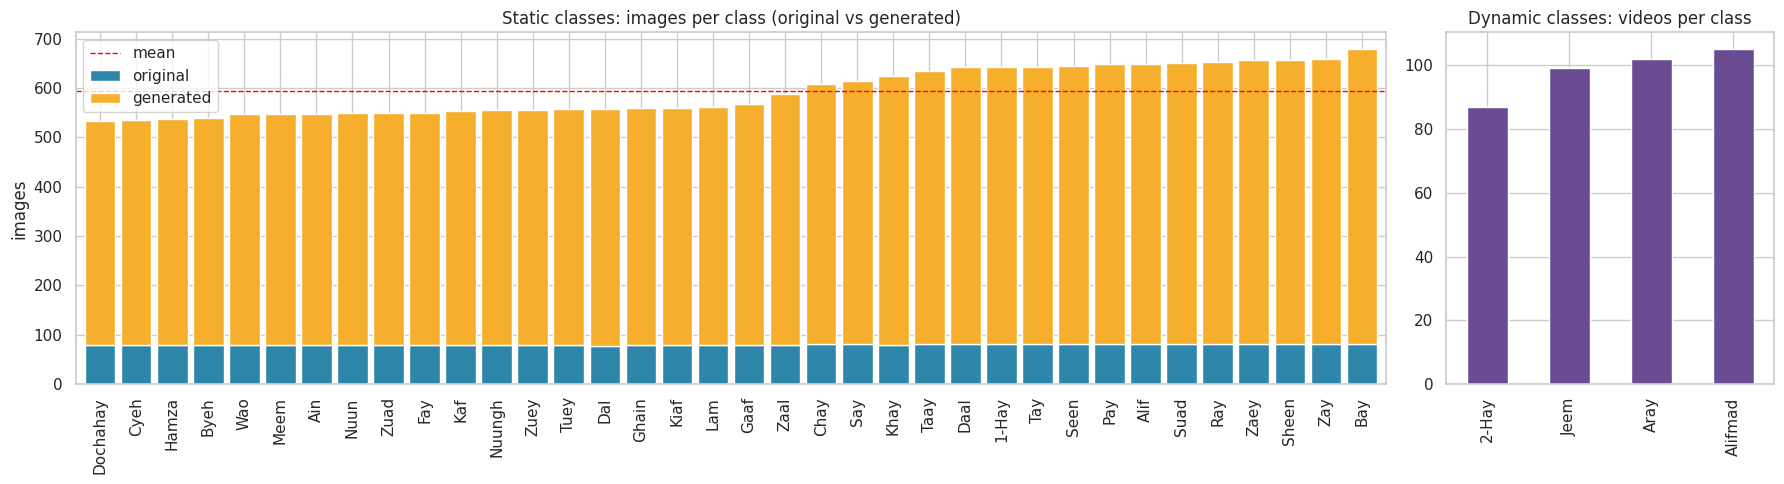

Static: min=533 (Dochahay), max=679 (Bay), ratio=1.27, normalised entropy=0.999 (1.0 = perfectly balanced)
Dynamic: min=87 (2-Hay), max=105 (Alifmad)
Average images per static class / videos per dynamic class: 593 / 98  -> static classes have 6.0x more samples


In [4]:
cls = imgs.groupby(['label', 'is_generated']).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
cls.columns = ['original', 'generated']
cls['total'] = cls.sum(axis=1)
cls = cls.sort_values('total')
vid_counts = vids['label'].value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [4, 1]})
cls[['original', 'generated']].plot(kind='bar', stacked=True, ax=axes[0], color=['#2E86AB', '#F6AE2D'], width=0.85)
axes[0].axhline(cls['total'].mean(), color='red', ls='--', lw=1, label='mean'); axes[0].legend()
axes[0].set_title('Static classes: images per class (original vs generated)'); axes[0].set_ylabel('images'); axes[0].set_xlabel('')
vid_counts.plot(kind='bar', ax=axes[1], color='#6A4C93'); axes[1].set_title('Dynamic classes: videos per class'); axes[1].set_xlabel('')
plt.tight_layout(); savefig('05_class_distribution.png'); plt.show()

p = cls['total'] / cls['total'].sum()
entropy_norm = float(-(p * np.log(p)).sum() / np.log(len(p)))
imb_static = cls['total'].max() / cls['total'].min()
print(f"Static: min={cls['total'].min()} ({cls['total'].idxmin()}), max={cls['total'].max()} ({cls['total'].idxmax()}), "
      f"ratio={imb_static:.2f}, normalised entropy={entropy_norm:.3f} (1.0 = perfectly balanced)")
print(f"Dynamic: min={vid_counts.min()} ({vid_counts.idxmin()}), max={vid_counts.max()} ({vid_counts.idxmax()})")
print(f"Average images per static class / videos per dynamic class: {cls['total'].mean():.0f} / {vid_counts.mean():.0f}  "
      f"-> static classes have {cls['total'].mean() / vid_counts.mean():.1f}x more samples")

**What it tells us:** static classes are close to balanced, so plain accuracy is a reasonable metric for the static model, but we will still report F1. The dynamic classes have far fewer samples (about 100 videos each), so the dynamic model is data-starved and will need augmentation or a small model.

## 3. Original vs generated images, and subjects

Original images: 2897 | generated: 18463 | generated share = 86.4%
Original images per class: min 78 | median 80 | max 82

Distinct subjects: 84
Images per subject: min 35 | median 36 | max 907
Subjects present per class: min 80 | median 82 | max 84


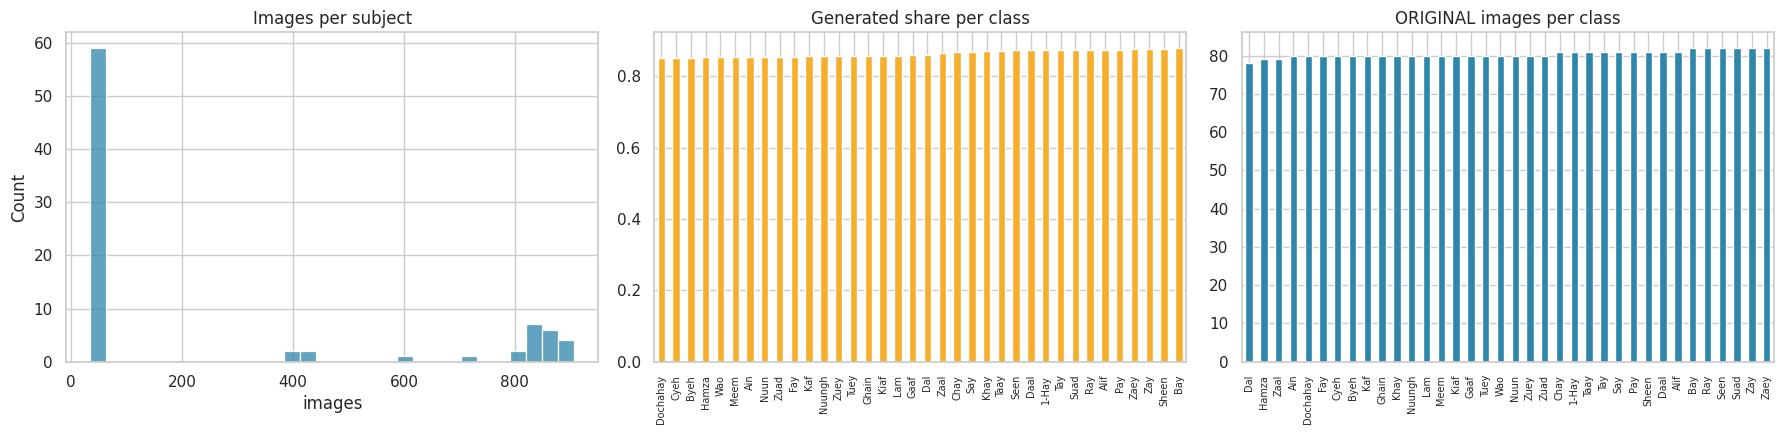

In [5]:
orig = imgs[~imgs['is_generated']]
print('Original images:', len(orig), '| generated:', int(imgs['is_generated'].sum()),
      f"| generated share = {imgs['is_generated'].mean():.1%}")
orig_per_class = orig.groupby('label').size()
print('Original images per class: min', orig_per_class.min(), '| median', int(orig_per_class.median()), '| max', orig_per_class.max())

subj_n = imgs.groupby('subject').size()
subj_cov = imgs.groupby('label')['subject'].nunique()
print('\nDistinct subjects:', imgs['subject'].nunique())
print('Images per subject: min', subj_n.min(), '| median', int(subj_n.median()), '| max', subj_n.max())
print('Subjects present per class: min', subj_cov.min(), '| median', int(subj_cov.median()), '| max', subj_cov.max())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(subj_n, bins=30, ax=axes[0], color='#2E86AB'); axes[0].set_title('Images per subject'); axes[0].set_xlabel('images')
gen_share = (cls['generated'] / cls['total']).sort_values()
gen_share.plot(kind='bar', ax=axes[1], color='#F6AE2D'); axes[1].set_title('Generated share per class'); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', labelsize=7)
orig_per_class.sort_values().plot(kind='bar', ax=axes[2], color='#2E86AB'); axes[2].set_title('ORIGINAL images per class'); axes[2].set_xlabel(''); axes[2].tick_params(axis='x', labelsize=7)
plt.tight_layout(); savefig('06_subjects_and_originals.png'); plt.show()

**What it tells us:** the generated share shows how much of the data is augmentation. Many generated images come from the same original photo, so a random train/test split would put near-copies of one photo on both sides and inflate test accuracy. **We must split by subject (person)**, not by image. The number of subjects per class tells us how many people we can distribute across train / validation / test.

## 4. Image properties: resolution, aspect ratio, brightness, blur

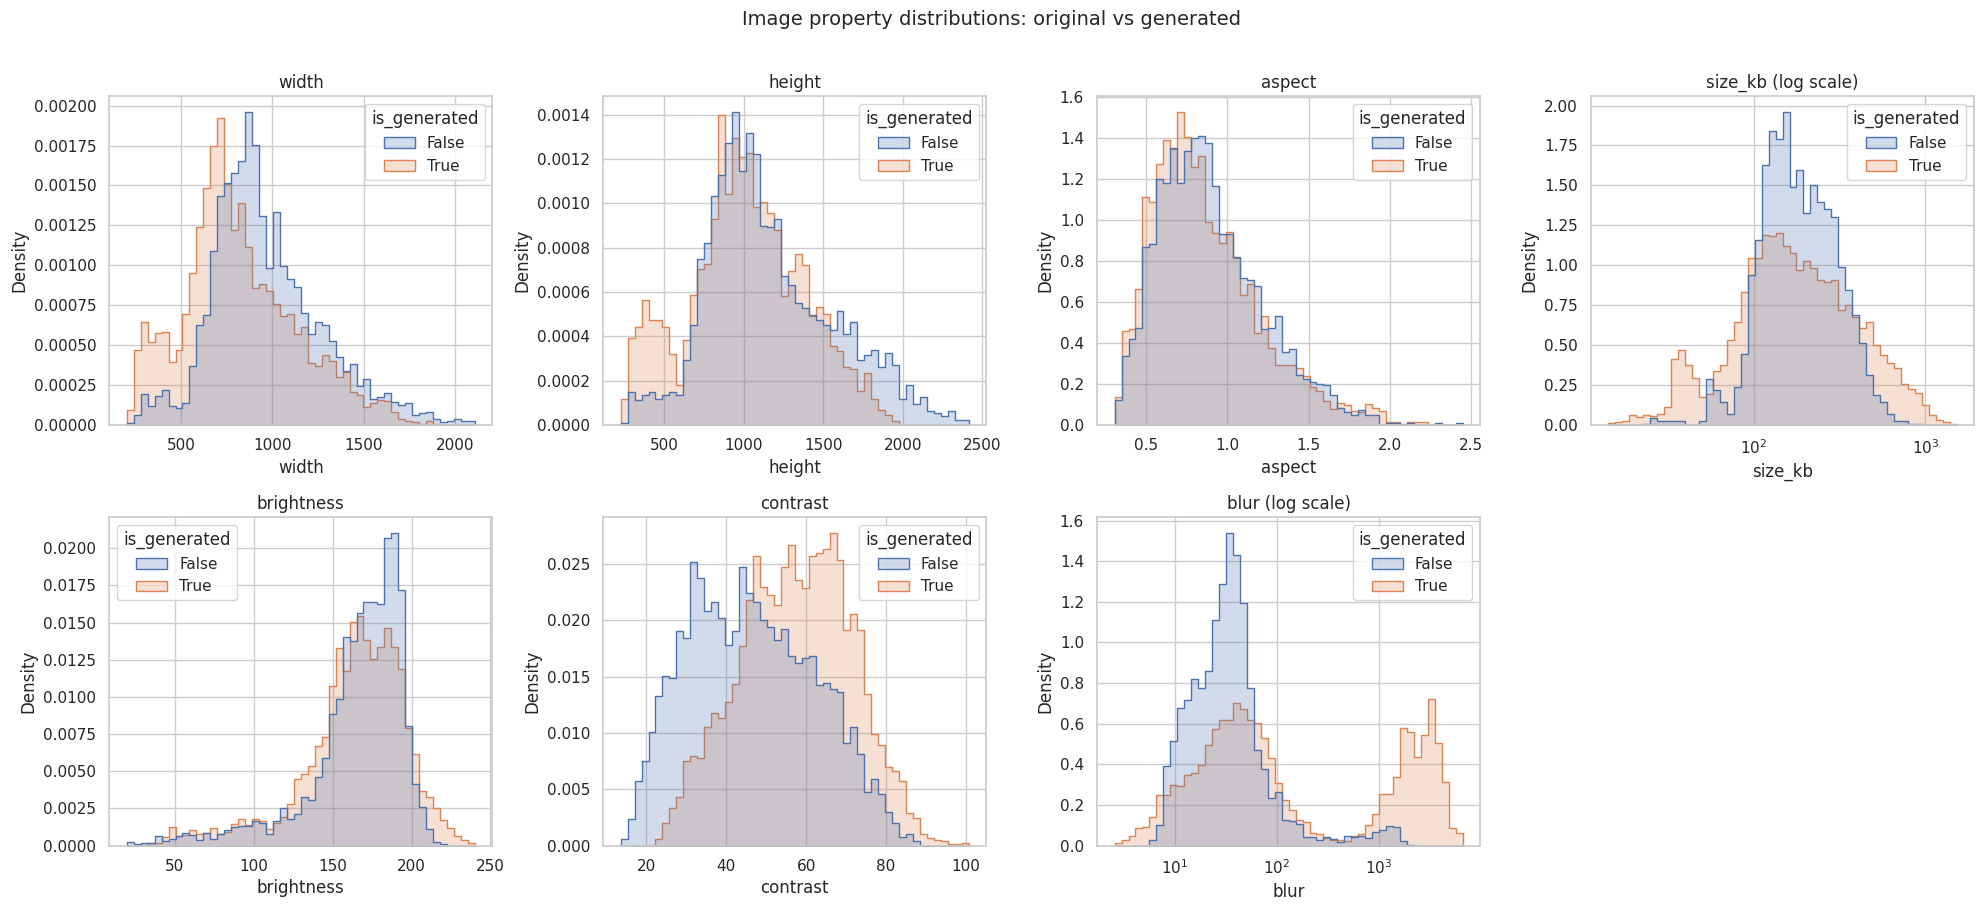

Orientation share: {'portrait': 0.657, 'landscape': 0.251, 'square': 0.092}
Aspect ratio percentiles (5/50/95): [0.45, 0.81, 1.51]


,width,height,size_kb,brightness,contrast,blur
is_generated,,,,,,
False,913.0,1082.0,176.9,172.5,45.4,31.7
True,770.0,1005.0,168.5,167.7,57.8,66.4


In [6]:
props = [('width', False), ('height', False), ('aspect', False), ('size_kb', True), ('brightness', False), ('contrast', False), ('blur', True)]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (c, lg) in zip(axes.ravel(), props):
    sns.histplot(data=imgs, x=c, hue='is_generated', bins=50, log_scale=lg, ax=ax, element='step', stat='density', common_norm=False)
    ax.set_title(c + (' (log scale)' if lg else ''))
axes.ravel()[-1].axis('off')
plt.suptitle('Image property distributions: original vs generated', y=1.01, fontsize=14)
plt.tight_layout(); savefig('07_image_property_histograms.png'); plt.show()

orient = np.where(imgs['aspect'] > 1.05, 'landscape', np.where(imgs['aspect'] < 0.95, 'portrait', 'square'))
orient_share = pd.Series(orient).value_counts(normalize=True).round(3)
print('Orientation share:', orient_share.to_dict())
print('Aspect ratio percentiles (5/50/95):', imgs['aspect'].quantile([.05, .5, .95]).round(2).tolist())
orig_vs_gen = imgs.groupby('is_generated')[['width', 'height', 'size_kb', 'brightness', 'contrast', 'blur']].median().round(1)
orig_vs_gen

**What it tells us:** resolution varies enormously (hundreds to 2,000+ px) and orientation is mixed, so every image must be resized to one fixed size. A plain stretch would distort the hand, so we will decide between padding to a square and a plain resize in the preprocessing notebook. Differences between original and generated curves (especially blur) show that generated images are not just copies, they have different sharpness.

## 5. Correlation between image properties

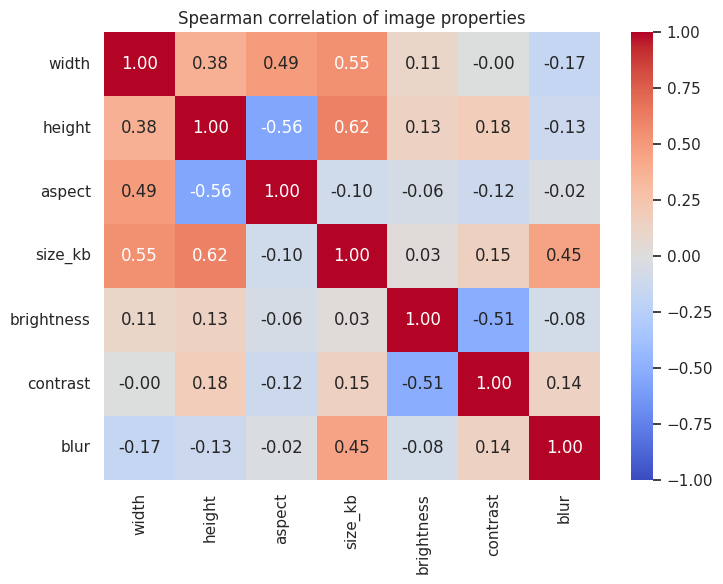

Strongest correlations:
height      size_kb     0.62
            aspect     -0.56
width       size_kb     0.55
brightness  contrast   -0.51
width       aspect      0.49


In [7]:
num_cols = ['width', 'height', 'aspect', 'size_kb', 'brightness', 'contrast', 'blur']
corr = imgs[num_cols].corr(method='spearman')
plt.figure(figsize=(7.5, 6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman correlation of image properties'); plt.tight_layout(); savefig('08_correlation_heatmap.png'); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print('Strongest correlations:'); print(pairs.head(5).round(2).to_string())

**What it tells us:** width, height and file size move together (bigger image, bigger file), so they carry the same information and we only need to keep one of them as a feature. The relationship of blur with the other properties shows whether sharpness is just a side effect of resolution.

## 6. Do image properties depend on the class (shortcut-learning check)

Share of variance explained by class (0 = none, 1 = all):
brightness    0.439
contrast      0.117
blur          0.003
width         0.413
height        0.317
aspect        0.746
size_kb       0.092


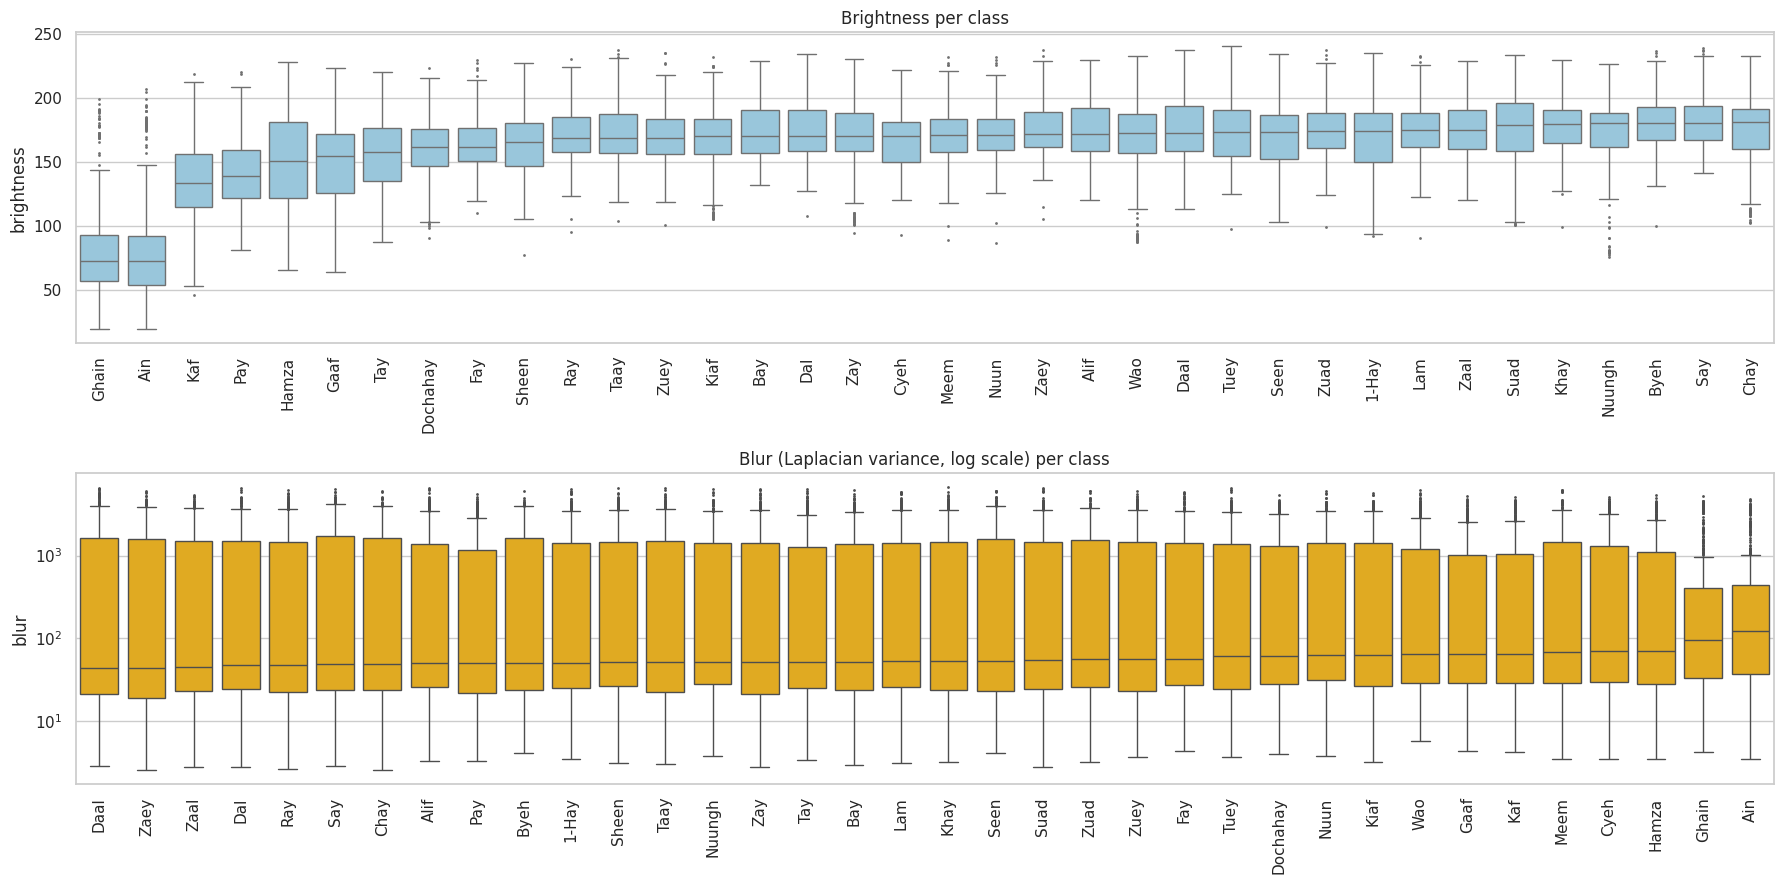

In [8]:
def eta2(d, col):
    g = d.groupby('label')[col]
    return float(((g.mean() - d[col].mean()) ** 2 * g.size()).sum() / ((d[col] - d[col].mean()) ** 2).sum())
eta = pd.Series({c: eta2(imgs, c) for c in ['brightness', 'contrast', 'blur', 'width', 'height', 'aspect', 'size_kb']}).round(3)
print('Share of variance explained by class (0 = none, 1 = all):'); print(eta.to_string())

fig, axes = plt.subplots(2, 1, figsize=(18, 9))
order_b = imgs.groupby('label')['brightness'].median().sort_values().index
sns.boxplot(data=imgs, x='label', y='brightness', order=order_b, ax=axes[0], color='#8ecae6', fliersize=1)
axes[0].set_title('Brightness per class'); axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=90)
order_l = imgs.groupby('label')['blur'].median().sort_values().index
sns.boxplot(data=imgs, x='label', y='blur', order=order_l, ax=axes[1], color='#ffb703', fliersize=1)
axes[1].set_yscale('log'); axes[1].set_title('Blur (Laplacian variance, log scale) per class'); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=90)
plt.tight_layout(); savefig('09_properties_by_class.png'); plt.show()

**What it tells us:** if a property is almost independent of the class (low value above), the classes were photographed under similar conditions and the model has to look at the hand. A high value would mean the class could be guessed from brightness or sharpness alone, which is a shortcut we would need to neutralise (e.g. brightness augmentation).

## 7. What the signs look like

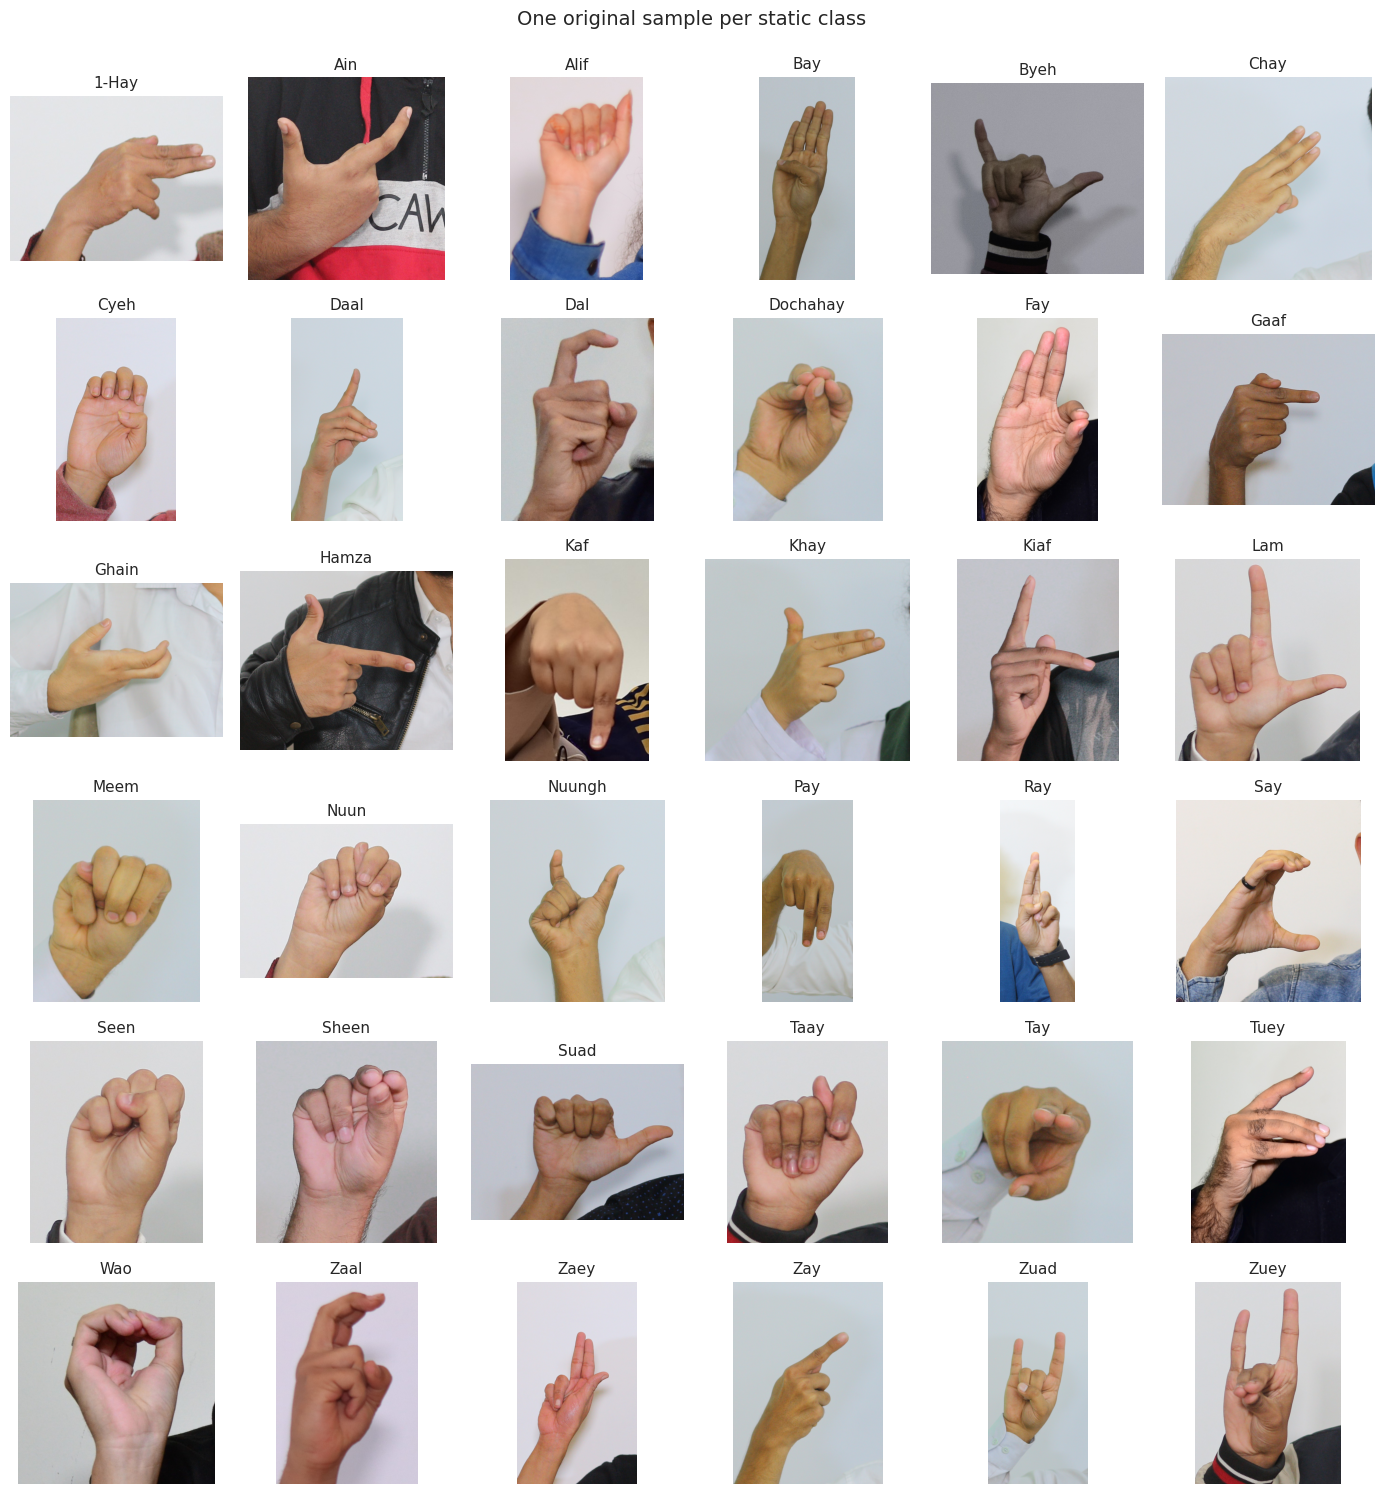

In [9]:
rng = np.random.RandomState(1)
fig, axes = plt.subplots(6, 6, figsize=(14, 15))
for ax, c in zip(axes.ravel(), STATIC):
    pool = imgs[(imgs['label'] == c) & (~imgs['is_generated'])]
    r = pool.sample(1, random_state=rng).iloc[0]
    ax.imshow(cv2.cvtColor(cv2.imread(r['path']), cv2.COLOR_BGR2RGB)); ax.set_title(c, fontsize=11); ax.axis('off')
plt.suptitle('One original sample per static class', y=0.995, fontsize=14)
plt.tight_layout(); savefig('10_sample_per_class.png'); plt.show()

**What it tells us:** the signs are hand shapes against varying backgrounds, with the hand covering only part of the frame. Visually similar signs here are the candidates for the confusions we measure next.

## 8. Which letters look alike


  0%|          | 0/36 [00:00<?, ?it/s]

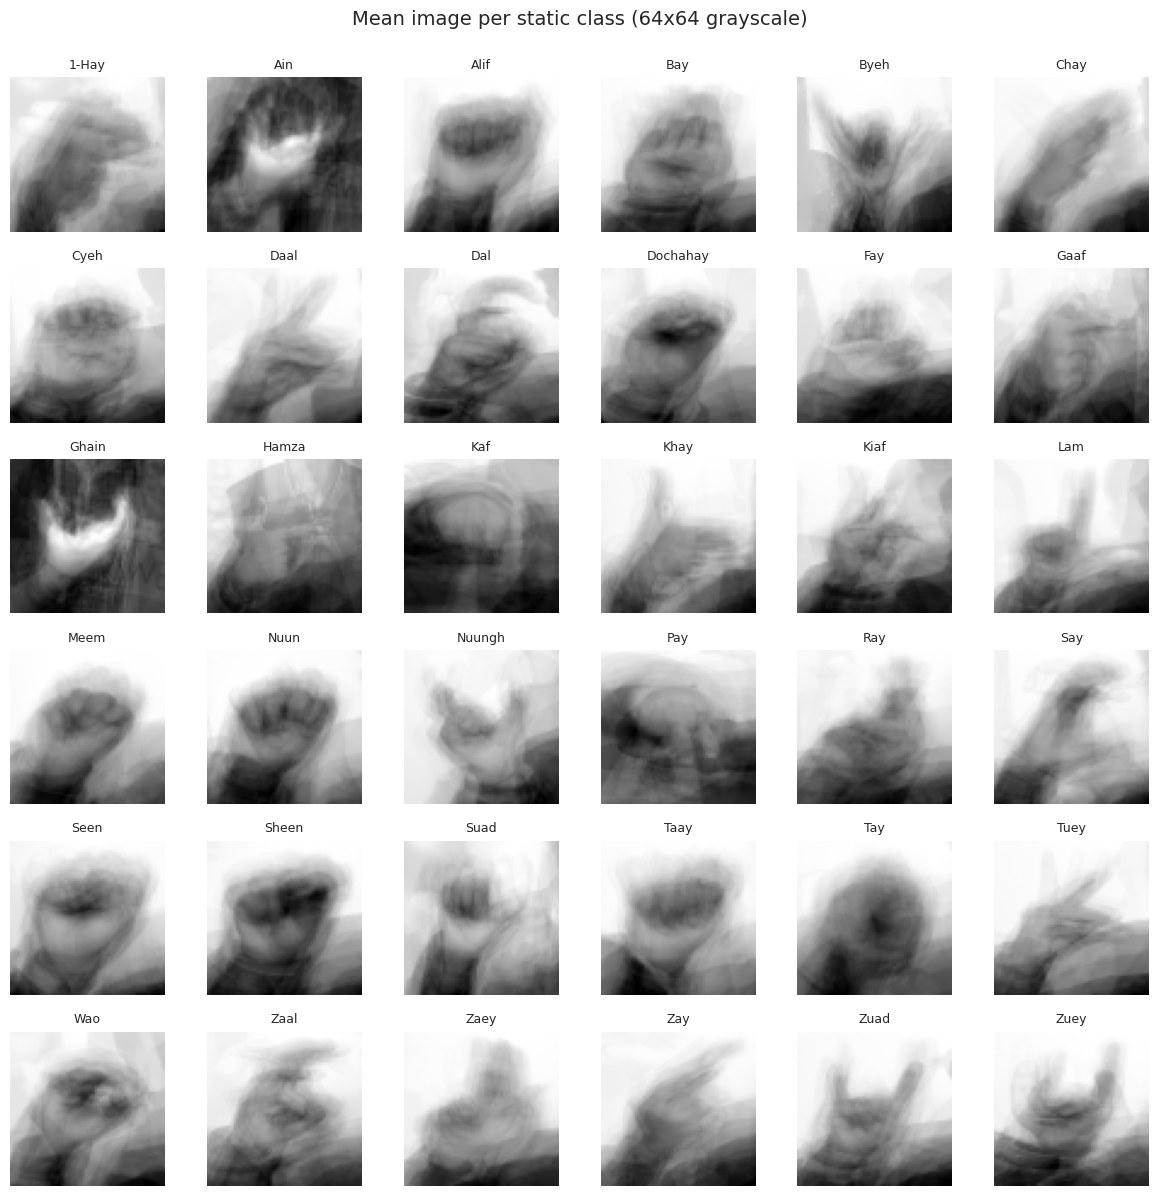

In [10]:
def load_small(path):
    g = cv2.imread(path, cv2.IMREAD_REDUCED_GRAYSCALE_4)
    if g is None: g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0

mean_imgs = {}
for c in tqdm(STATIC):
    sample = imgs[imgs['label'] == c].sample(min(40, (imgs['label'] == c).sum()), random_state=0)['path'].tolist()
    with ThreadPoolExecutor(max_workers=8) as ex:
        arr = list(ex.map(load_small, sample))
    mean_imgs[c] = np.mean(arr, axis=0)

fig, axes = plt.subplots(6, 6, figsize=(12, 12))
for ax, c in zip(axes.ravel(), STATIC):
    ax.imshow(mean_imgs[c], cmap='gray'); ax.set_title(c, fontsize=9); ax.axis('off')
plt.suptitle('Mean image per static class (64x64 grayscale)', y=0.995, fontsize=14)
plt.tight_layout(); savefig('11_mean_images.png'); plt.show()

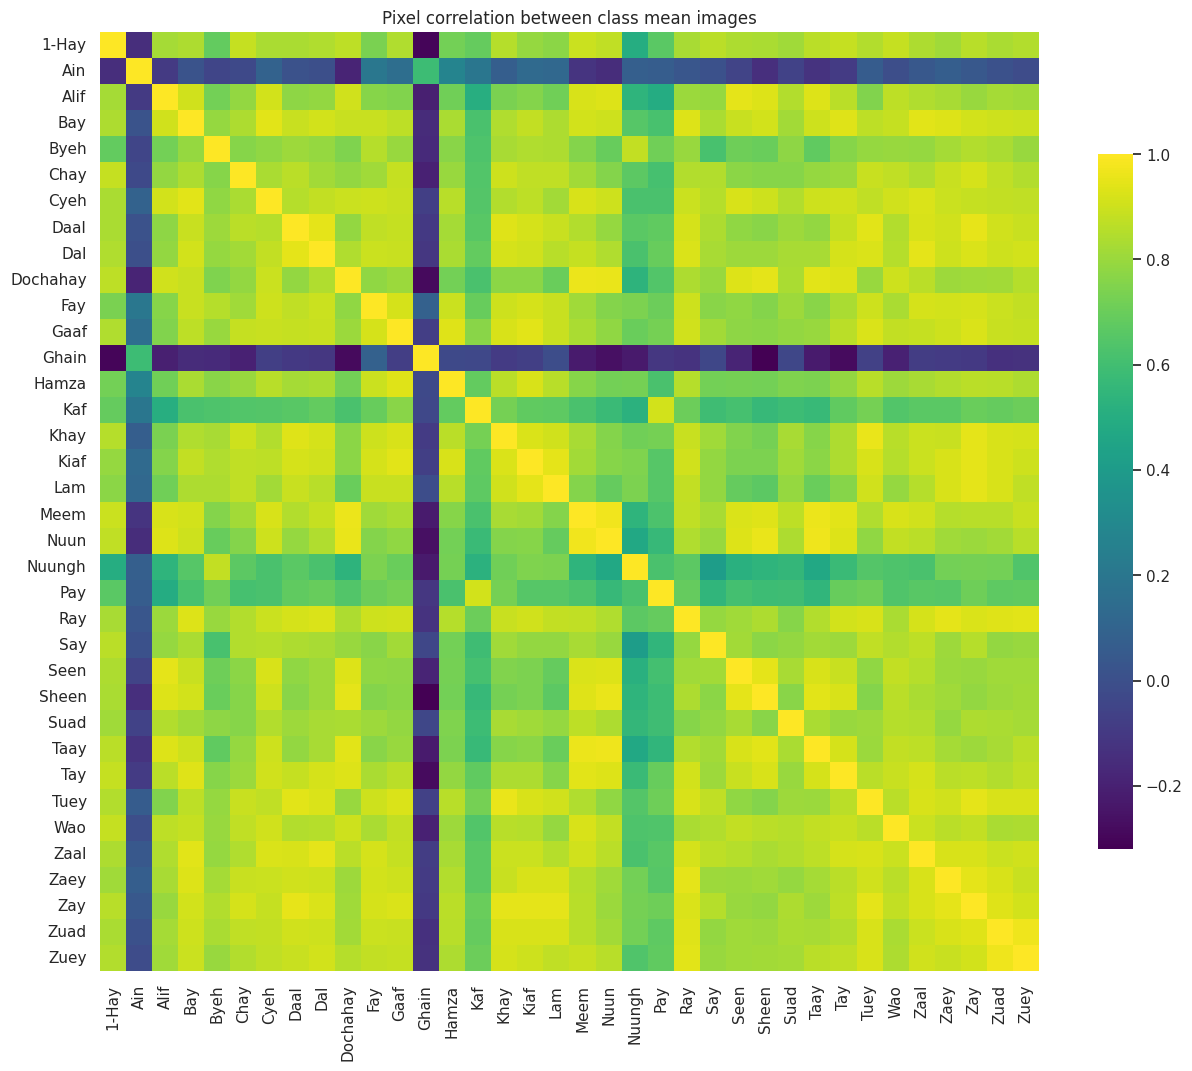

10 most similar class pairs:
Meem      Nuun     0.973
Nuun      Taay     0.968
Zuad      Zuey     0.966
Meem      Taay     0.960
Dochahay  Meem     0.960
Khay      Tuey     0.955
Dochahay  Nuun     0.954
Nuun      Sheen    0.954
Daal      Zay      0.950
Tuey      Zay      0.947


In [11]:
M = np.stack([mean_imgs[c].ravel() for c in STATIC])
Z = M - M.mean(axis=1, keepdims=True); Z /= np.linalg.norm(Z, axis=1, keepdims=True)
C = Z @ Z.T
sim = pd.DataFrame(C, index=STATIC, columns=STATIC)
plt.figure(figsize=(13, 11)); sns.heatmap(sim, cmap='viridis', square=True, cbar_kws={'shrink': .7})
plt.title('Pixel correlation between class mean images'); plt.tight_layout(); savefig('12_class_similarity.png'); plt.show()

pairs_sim = sim.where(np.triu(np.ones(sim.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
top_pairs = pairs_sim.head(10).round(3)
print('10 most similar class pairs:'); print(top_pairs.to_string())

**What it tells us:** bright off-diagonal cells and the top-pair list mark letters whose average appearance is nearly identical. After training we will check whether the confusion matrix confuses exactly these pairs. If so, it is a data property rather than a model failure.

## 9. Normalization statistics (pixel mean and standard deviation)

In [12]:
NS = 1500
ns_paths = imgs.sample(NS, random_state=0)['path'].tolist()
def load_rgb(path):
    im = cv2.imread(path, cv2.IMREAD_REDUCED_COLOR_4)
    if im is None: im = cv2.imread(path)
    im = cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (224, 224), interpolation=cv2.INTER_AREA).astype(np.float64) / 255.0
    return im.reshape(-1, 3).sum(0), (im.reshape(-1, 3) ** 2).sum(0), im.shape[0] * im.shape[1]
with ThreadPoolExecutor(max_workers=8) as ex:
    res = list(tqdm(ex.map(load_rgb, ns_paths), total=NS))
n = sum(r[2] for r in res)
ch_mean = sum(r[0] for r in res) / n
ch_std = np.sqrt(sum(r[1] for r in res) / n - ch_mean ** 2)
print('Dataset RGB mean:', ch_mean.round(4).tolist()); print('Dataset RGB std :', ch_std.round(4).tolist())
print('ImageNet RGB mean:', [0.485, 0.456, 0.406], ' std:', [0.229, 0.224, 0.225])
json.dump({'rgb_mean': ch_mean.tolist(), 'rgb_std': ch_std.tolist(), 'n_images': NS, 'resize': 224}, open(os.path.join(OUT, 'channel_stats.json'), 'w'))

  0%|          | 0/1500 [00:00<?, ?it/s]

Dataset RGB mean: [0.6878, 0.6238, 0.6011]
Dataset RGB std : [0.2532, 0.2667, 0.2795]
ImageNet RGB mean: [0.485, 0.456, 0.406]  std: [0.229, 0.224, 0.225]


**What it tells us:** these are the values we will use to standardise pixels in the preprocessing notebook. If they are close to ImageNet's, the ImageNet normalisation (what MobileNetV2 / EfficientNet expect) is a safe choice for transfer learning.

## 10. Can a hand be detected (MediaPipe)
The dynamic model and the optional landmark approach depend on MediaPipe finding the hand. We test a sample: 15 images per static class, and 6 evenly spaced frames from up to 10 videos per dynamic class. Low detection rates for a class mean the landmark approach will be unreliable there.

static:   0%|          | 0/36 [00:00<?, ?it/s]

dynamic:   0%|          | 0/4 [00:00<?, ?it/s]

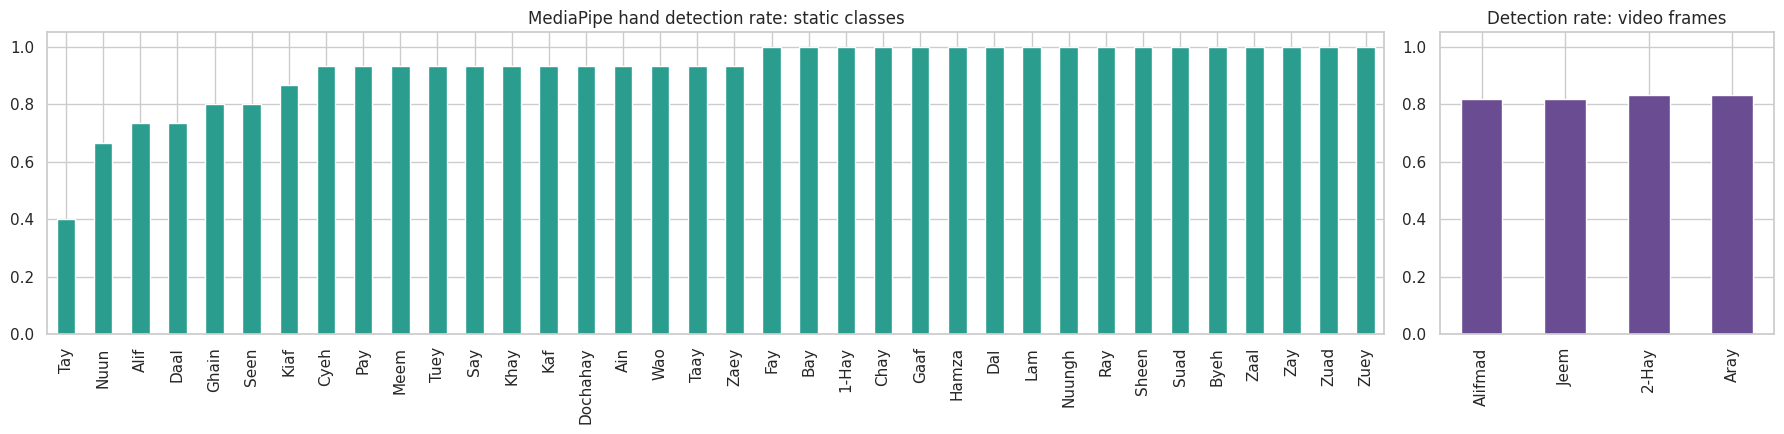

Overall detection: static 92.2% | video frames 82.5%
Lowest 5 static classes:
label
Tay      0.40
Nuun     0.67
Alif     0.73
Daal     0.73
Ghain    0.80


In [14]:
hd_static, hd_vid = None, None
try:
    import urllib.request
    import mediapipe as mp
    from mediapipe.tasks import python as mp_python
    from mediapipe.tasks.python import vision

    MODEL = '/content/hand_landmarker.task'
    if not os.path.exists(MODEL):
        urllib.request.urlretrieve(
            'https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task', MODEL)

    options = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=0.5)
    landmarker = vision.HandLandmarker.create_from_options(options)

    def detect(bgr):
        h, w = bgr.shape[:2]; s = 640 / max(h, w)
        if s < 1: bgr = cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        rgb = np.ascontiguousarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
        return len(res.hand_landmarks)

    rows = []
    for c in tqdm(STATIC, desc='static'):
        for p in imgs[imgs['label'] == c].sample(15, random_state=0)['path']:
            rows.append({'label': c, 'n_hands': detect(cv2.imread(p))})
    hd_static = pd.DataFrame(rows); hd_static['detected'] = hd_static['n_hands'] > 0

    rows = []
    for c in tqdm(DYNAMIC, desc='dynamic'):
        for p in vids[vids['label'] == c].sample(min(10, (vids['label'] == c).sum()), random_state=0)['path']:
            cap = cv2.VideoCapture(p); nf = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            for idx in np.linspace(0, max(nf - 1, 0), 6).astype(int):
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok_, fr = cap.read()
                if ok_: rows.append({'label': c, 'n_hands': detect(fr)})
            cap.release()
    hd_vid = pd.DataFrame(rows); hd_vid['detected'] = hd_vid['n_hands'] > 0

    rate_s = hd_static.groupby('label')['detected'].mean().sort_values()
    rate_v = hd_vid.groupby('label')['detected'].mean().sort_values()
    fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={'width_ratios': [4, 1]})
    rate_s.plot(kind='bar', ax=axes[0], color='#2A9D8F'); axes[0].set_ylim(0, 1.05); axes[0].set_title('MediaPipe hand detection rate: static classes'); axes[0].set_xlabel('')
    rate_v.plot(kind='bar', ax=axes[1], color='#6A4C93'); axes[1].set_ylim(0, 1.05); axes[1].set_title('Detection rate: video frames'); axes[1].set_xlabel('')
    plt.tight_layout(); savefig('13_hand_detection_rate.png'); plt.show()
    print(f"Overall detection: static {hd_static['detected'].mean():.1%} | video frames {hd_vid['detected'].mean():.1%}")
    print('Lowest 5 static classes:'); print(rate_s.head(5).round(2).to_string())
except Exception as e:
    print('MediaPipe step skipped:', repr(e))

**What it tells us:** classes with a low detection rate cannot rely on hand landmarks. For those we would need the image-based CNN, which is one more argument for the hybrid design in the proposal.

## 11. Dynamic signs (videos)

In [15]:
print('Video resolutions:', vids.groupby(['width', 'height']).size().to_dict())
print('FPS values:', vids['fps'].value_counts().to_dict())
pct = vids['frames'].quantile([.5, .9, .95, .99, 1.0]).astype(int)
print('Frames per video percentiles (50/90/95/99/max):', pct.tolist())
print('Total frames across all videos:', int(vids['frames'].sum()))
vids.groupby('label')[['frames', 'duration_s']].agg(['mean', 'min', 'max']).round(2)

Video resolutions: {(1920.0, 1080.0): 393}
FPS values: {30.0: 393}
Frames per video percentiles (50/90/95/99/max): [55, 81, 88, 100, 118]
Total frames across all videos: 22677


frames              duration_s            
          mean   min    max       mean   min   max
label                                             
2-Hay    66.87  26.0  118.0       2.23  0.87  3.93
Alifmad  51.50  23.0   94.0       1.72  0.77  3.13
Aray     56.65  13.0   94.0       1.89  0.43  3.13
Jeem     57.31  21.0   94.0       1.91  0.70  3.13

  0%|          | 0/393 [00:00<?, ?it/s]

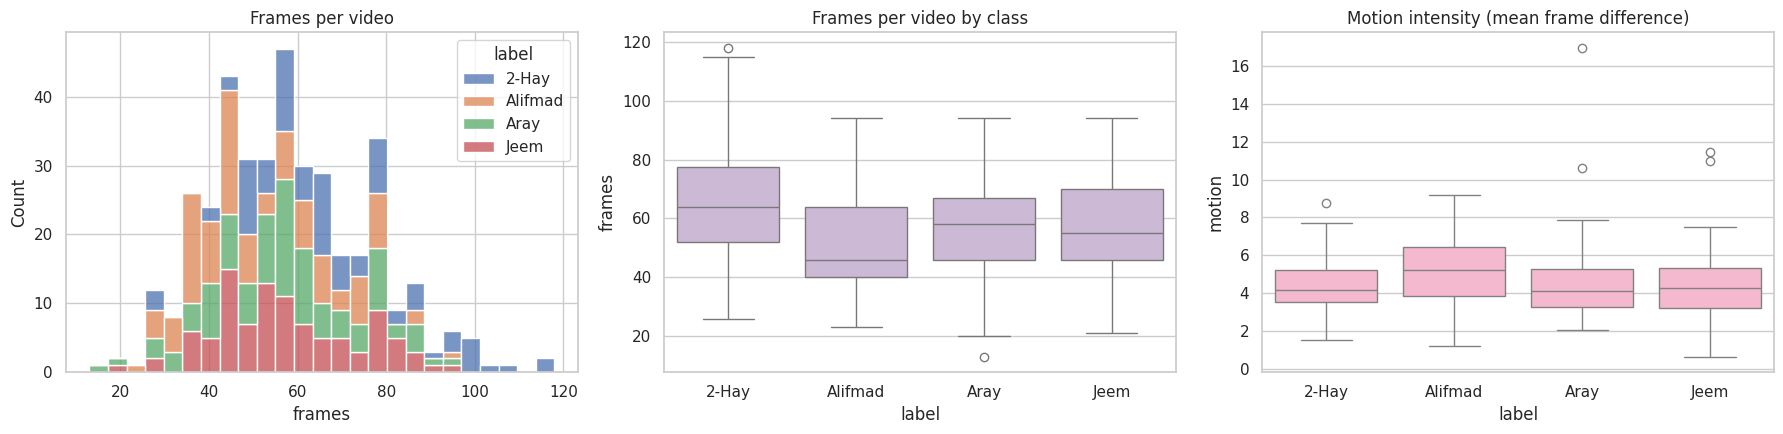

Median motion per class:
label
2-Hay      4.17
Alifmad    5.20
Aray       4.10
Jeem       4.26


In [16]:
def motion(path):
    cap = cv2.VideoCapture(path); prev = None; diffs = []
    while True:
        ok_, fr = cap.read()
        if not ok_: break
        g = cv2.resize(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
        if prev is not None: diffs.append(np.abs(g - prev).mean())
        prev = g
    cap.release()
    return float(np.mean(diffs)) if diffs else np.nan
with ThreadPoolExecutor(max_workers=4) as ex:
    vids['motion'] = list(tqdm(ex.map(motion, vids['path']), total=len(vids)))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(data=vids, x='frames', hue='label', multiple='stack', bins=25, ax=axes[0]); axes[0].set_title('Frames per video')
sns.boxplot(data=vids, x='label', y='frames', ax=axes[1], color='#cdb4db'); axes[1].set_title('Frames per video by class')
sns.boxplot(data=vids, x='label', y='motion', ax=axes[2], color='#ffafcc'); axes[2].set_title('Motion intensity (mean frame difference)')
plt.tight_layout(); savefig('14_video_stats.png'); plt.show()
print('Median motion per class:'); print(vids.groupby('label')['motion'].median().round(2).to_string())

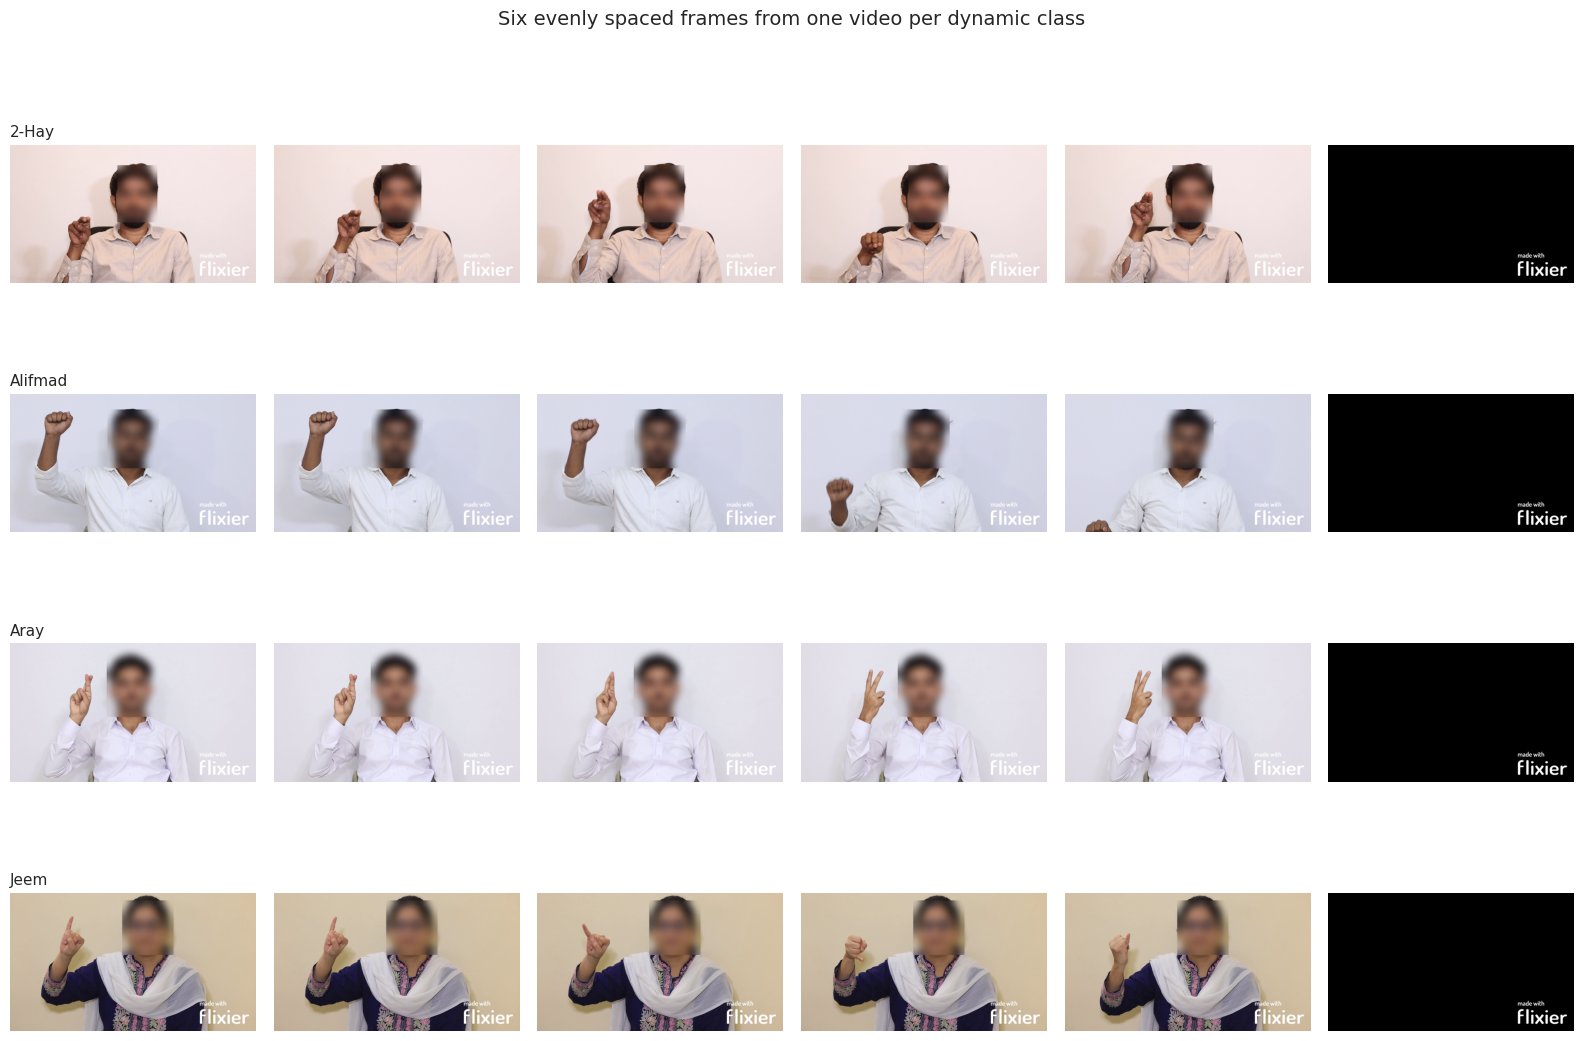

In [17]:
fig, axes = plt.subplots(len(DYNAMIC), 6, figsize=(16, 2.8 * len(DYNAMIC)))
for r, c in enumerate(DYNAMIC):
    p = vids[vids['label'] == c].sample(1, random_state=3).iloc[0]['path']
    cap = cv2.VideoCapture(p); nf = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for k, idx in enumerate(np.linspace(0, nf - 1, 6).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok_, fr = cap.read()
        axes[r, k].axis('off')
        if ok_: axes[r, k].imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        if k == 0: axes[r, k].set_title(c, loc='left', fontsize=11)
    cap.release()
plt.suptitle('Six evenly spaced frames from one video per dynamic class', y=1.0, fontsize=14)
plt.tight_layout(); savefig('15_video_frame_strips.png'); plt.show()

**What it tells us:** the 95th-percentile frame count gives a sensible fixed sequence length for the LSTM (shorter videos are padded, longer ones trimmed or subsampled). The motion plot shows whether the four dynamic signs differ in how much movement they contain, and the frame strips show how the motion actually unfolds.

In [18]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)

hdr('Sizes'); print('Images:', len(imgs), '| Videos:', len(vids), '| static classes:', len(STATIC), '| dynamic:', len(DYNAMIC))
hdr('Class balance')
print(cls['total'].describe().round(1).to_string()); print('Imbalance ratio (static):', round(imb_static, 2), '| normalised entropy:', round(entropy_norm, 3))
print('Smallest 5 static:'); print(cls['total'].head(5).to_string()); print('Largest 5 static:'); print(cls['total'].tail(5).to_string())
print('Videos per class:'); print(vid_counts.to_string())
hdr('Original vs generated and subjects')
print('Original:', len(orig), '| generated:', int(imgs['is_generated'].sum()), '| generated share:', round(imgs['is_generated'].mean(), 3))
print('Originals per class (min/median/max):', orig_per_class.min(), int(orig_per_class.median()), orig_per_class.max())
print('Subjects:', imgs['subject'].nunique(), '| images per subject (min/median/max):', subj_n.min(), int(subj_n.median()), subj_n.max())
print('Subjects per class (min/median/max):', subj_cov.min(), int(subj_cov.median()), subj_cov.max())
print('Generated share per class (min/max):', round(gen_share.min(), 3), round(gen_share.max(), 3))
hdr('Image properties')
print(imgs[['width', 'height', 'aspect', 'size_kb', 'brightness', 'contrast', 'blur']].describe().round(2).to_string())
print('Orientation share:', orient_share.to_dict()); print('Original vs generated medians:'); print(orig_vs_gen.to_string())
hdr('Strongest correlations'); print(pairs.head(6).round(2).to_string())
hdr('Class effect on properties (eta squared)'); print(eta.to_string())
hdr('Most similar class pairs'); print(top_pairs.to_string())
hdr('Normalization'); print('RGB mean:', ch_mean.round(4).tolist(), '| RGB std:', ch_std.round(4).tolist())
hdr('Hand detection')
if hd_static is not None:
    print('Static overall:', round(hd_static['detected'].mean(), 3), '| video frames overall:', round(hd_vid['detected'].mean(), 3))
    print('Static detection rate, lowest 8 classes:'); print(hd_static.groupby('label')['detected'].mean().sort_values().head(8).round(2).to_string())
    print('Video detection rate per class:'); print(hd_vid.groupby('label')['detected'].mean().round(2).to_string())
else:
    print('MediaPipe step was skipped')
hdr('Videos')
print('Frames percentiles (50/90/95/99/max):', pct.tolist()); print('FPS:', vids['fps'].value_counts().to_dict())
print(vids.groupby('label')[['frames', 'duration_s', 'motion']].agg(['mean', 'min', 'max']).round(2).to_string())


Sizes
Images: 21360 | Videos: 393 | static classes: 36 | dynamic: 4

Class balance
count     36.0
mean     593.3
std       48.3
min      533.0
25%      549.8
50%      565.0
75%      643.5
max      679.0
Imbalance ratio (static): 1.27 | normalised entropy: 0.999
Smallest 5 static:
label
Dochahay    533
Cyeh        535
Hamza       538
Byeh        539
Wao         547
Largest 5 static:
label
Ray      653
Zaey     657
Sheen    657
Zay      658
Bay      679
Videos per class:
label
2-Hay       87
Jeem        99
Aray       102
Alifmad    105

Original vs generated and subjects
Original: 2897 | generated: 18463 | generated share: 0.864
Originals per class (min/median/max): 78 80 82
Subjects: 84 | images per subject (min/median/max): 35 36 907
Subjects per class (min/median/max): 80 82 84
Generated share per class (min/max): 0.85 0.879

Image properties
          width    height    aspect   size_kb  brightness  contrast      blur
count  21360.00  21360.00  21360.00  21360.00    21360.00  21360.